# Breaking a bar with gradient damage

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 8, Section "Damage", Example "Breaking a Bar".

A bar of length $L$, fixed at $x = 0$, is stretched by $u(L) = tL$. At each load step the displacement $u$ and the
damage $\alpha$ minimize
$$\mathcal{E}(u, \alpha) = \int_0^L \Big( \frac12\, E_0\, \mathsf{m}(\alpha)\, (u')^2 + \mathsf{r}\,\alpha
  + \frac{\mathsf{r}\,\ell^2}{2}\, (\alpha')^2 \Big)\, dx, \qquad \mathsf{m}(\alpha) = (1 - \alpha)^2 + \eta ,$$
under the irreversibility constraint $\alpha_{\rm previous} \le \alpha \le 1$. The homogeneous response would reach the
peak stress $\sigma_c = \sqrt{E_0\,\mathsf r}$ at $t_c = \sqrt{\mathsf r/E_0}$ and then soften; but it is unstable, and
the damage localizes in a band of width $2\sqrt2\,\ell$, where the bar breaks after dissipating the toughness
$G_c = \frac{4\sqrt2}{3}\,\mathsf r\,\ell$.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
E0, r_    = 1.0, 1.0       # Young's modulus and dissipation per unit damage: sigma_c = t_c = 1
L, ell    = 1.0, 0.05      # length of the bar and internal length (L = 20 ell)
eta       = 1e-6           # residual stiffness of the broken material
N         = 400            # linear elements (h = ell/20)
defect    = 0.01           # the section at midspan is weaker: r lower by 1% over a width of about ell
t_steps   = np.r_[np.linspace(0, 0.98, 50), np.linspace(0.99, 1.2, 22)]   # imposed strain t = u(L)/L
# ---------------------------------------------------------------------------

## 1. The two minimizations

- *Displacement, at fixed damage*: a bar with the stiffness $E_0\,\mathsf m(\alpha)$, integrated exactly with two
  Gauss points per element, since $\alpha$ is linear and $\mathsf m$ quadratic; the end displacement is eliminated.
- *Damage, at fixed displacement*: a convex quadratic function of the nodal values of $\alpha$, to be minimized under
  the bounds $\alpha_{\rm previous} \le \alpha \le 1$, a discrete obstacle problem. We give it, with its gradient, to
  the bound-constrained minimizer L-BFGS-B of SciPy.
- *Alternate minimization*: the two steps are repeated until the damage changes by less than $10^{-6}$.

In [2]:
h = L / N
x = np.linspace(0, L, N + 1)
xm = 0.5 * (x[:-1] + x[1:])
r = r_ * (1 - defect * np.exp(-((xm - L / 2) / ell)**2))      # dissipation per unit damage, element by element
D = sp.diags([-np.ones(N), np.ones(N)], [0, 1], shape=(N, N + 1)).tocsr() / h   # nodal values -> element slopes
g = 0.5 / np.sqrt(3)
gauss = [(0.5 + g, 0.5 - g), (0.5 - g, 0.5 + g)]               # two Gauss points on each element, weights 1/2
m = lambda a: (1 - a)**2 + eta

def stiffness(alpha):                                          # element mean of E0 m(alpha), exact
    return E0 * sum(0.5 * m(c1 * alpha[:-1] + c2 * alpha[1:]) for c1, c2 in gauss)

def solve_u(alpha, t):
    K = D.T @ sp.diags(h * stiffness(alpha)) @ D
    u = np.zeros(N + 1); u[-1] = t * L
    free = np.arange(1, N)
    u[free] = spla.spsolve(K[free][:, free].tocsc(), -K[free][:, [N]] @ u[[N]])
    return u

def energy_alpha(alpha, eps2):                                 # energy and gradient in alpha, at fixed strain
    E, grad = 0.0, np.zeros(N + 1)
    for c1, c2 in gauss:
        a = c1 * alpha[:-1] + c2 * alpha[1:]
        E += np.sum(0.25 * E0 * eps2 * m(a) * h)
        f = 0.25 * E0 * eps2 * (-2 * (1 - a)) * h
        grad[:-1] += f * c1; grad[1:] += f * c2
    E += np.sum(0.5 * r * h * (alpha[:-1] + alpha[1:]))
    grad[:-1] += 0.5 * r * h; grad[1:] += 0.5 * r * h
    da = np.diff(alpha) / h
    E += np.sum(0.5 * r_ * ell**2 * da**2 * h)
    grad[:-1] -= r_ * ell**2 * da; grad[1:] += r_ * ell**2 * da
    return E, grad

def dissipated(alpha):
    return np.sum(0.5 * r * h * (alpha[:-1] + alpha[1:])) + np.sum(0.5 * r_ * ell**2 * np.diff(alpha)**2 / h)

alpha, history = np.zeros(N + 1), []
for t in t_steps:
    lower = alpha.copy()                                       # irreversibility: the damage of the previous step
    for it in range(500):
        u = solve_u(alpha, t)
        eps2 = (np.diff(u) / h)**2
        res = minimize(energy_alpha, alpha, args=(eps2,), jac=True, method="L-BFGS-B",
                       bounds=list(zip(lower, np.ones(N + 1))), options={"ftol": 1e-14, "gtol": 1e-10})
        change, alpha = np.abs(res.x - alpha).max(), res.x
        if change < 1e-6:
            break
    u = solve_u(alpha, t)
    sigma = np.mean(stiffness(alpha) * np.diff(u) / h)         # uniform stress
    history.append((t, sigma, alpha.max(), dissipated(alpha)))
history = np.array(history)
Gc = 4 * np.sqrt(2) / 3 * r_ * ell
print(f"peak stress {history[:, 1].max():.4f} (sigma_c = {np.sqrt(E0 * r_):.4f})")
print(f"dissipated energy at the end {history[-1, 3]:.4f}, toughness G_c = {Gc:.4f}")

peak stress 0.9900 (sigma_c = 1.0000)
dissipated energy at the end 0.0987, toughness G_c = 0.0943


## 2. The response of the bar

Left: the stress against the imposed strain. The bar is elastic up to $\sigma_c$, and then breaks in one step: the
elastic energy stored at the peak, $\sigma_c^2 L/2E_0$, is much larger than the toughness, and the bar cannot follow
a softening branch. The dashed line is the homogeneous response, which is unstable and is never observed.
Right: the damage profile against the exact one, $\alpha = (1 - |x - x_0|/\sqrt2\ell)^2$. The crack itself, where
$\alpha \approx 1$, occupies one or two elements; the exact profile is drawn split by the width $w$ of this zone.

width of the damaged band 0.1400, exact 2 sqrt(2) ell = 0.1414
the crack occupies 2 element(s); largest difference from the exact profile 0.0021


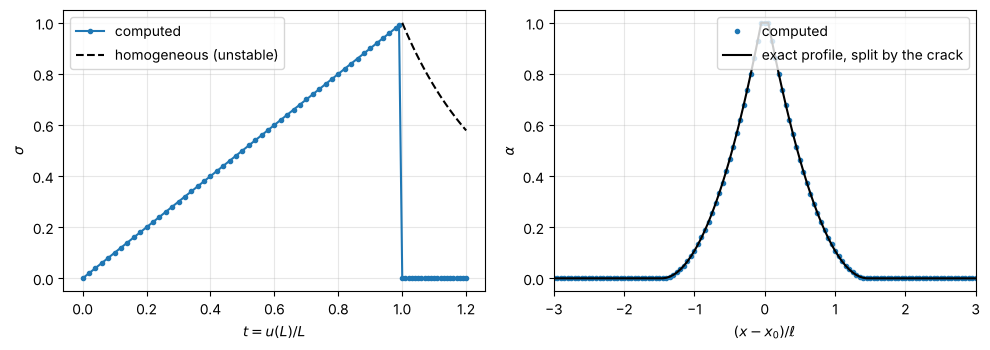

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
tc = np.sqrt(r_ / E0); tt = np.linspace(tc, t_steps[-1], 100)
a1.plot(history[:, 0], history[:, 1], "o-", ms=3, label="computed")
a1.plot(tt, np.sqrt(E0 * r_) * (tc / tt)**3, "k--", label="homogeneous (unstable)")
a1.set_xlabel("$t = u(L)/L$"); a1.set_ylabel(r"$\sigma$"); a1.legend(); a1.grid(alpha=0.3)
crack = x[alpha > 0.99]                                       # the broken elements
x0, w = crack.mean(), np.ptp(crack)
s_ = np.maximum(np.abs(x - x0) - w / 2, 0)                     # distance from the crack
exact = np.where(s_ < np.sqrt(2) * ell, (1 - s_ / (np.sqrt(2) * ell))**2, 0)
a2.plot((x - x0) / ell, alpha, "o", ms=3, label="computed")
a2.plot((x - x0) / ell, exact, "k-", label="exact profile, split by the crack")
a2.set_xlim(-3, 3); a2.set_xlabel(r"$(x - x_0)/\ell$"); a2.set_ylabel(r"$\alpha$"); a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"width of the damaged band {np.ptp(x[alpha > 1e-3]):.4f}, exact 2 sqrt(2) ell = {2 * np.sqrt(2) * ell:.4f}")
print(f"the crack occupies {round(w / h)} element(s); largest difference from the exact profile {np.abs(alpha - exact).max():.4f}")

## Things to try
1. Set `defect = 0`. The homogeneous state is unstable, but it is a stationary point, and an algorithm that only
   goes downhill does not leave it by itself: the bar first damages everywhere, then breaks. How much more energy
   does it dissipate?
2. Refine the mesh, `N = 800`: how do the width of the band and the dissipated energy approach the exact values?
3. Shorten the bar to `L = 0.1` (two internal lengths): the elastic energy at the peak is now smaller than the
   toughness. Does the bar still break in one step?
4. Remove the gradient term (`ell = 1e-4` with `N = 400`): the band is one element wide. Halve the mesh size and
   watch the dissipated energy.